# Day 07: Vision, evals and observability

Today we build one small app, an **invoice photo → validated JSON** extractor, and then ask the three questions every production AI feature needs answered:

1. **Does it work?** Vision + Pydantic + validation
2. **How well, and did my change break it?** Golden dataset, metrics, regression tests
3. **What is it doing in production?** Tracing, logging, monitoring, debugging

| § | Topic |
|---|---|
| 1 | Vision LLMs: image input |
| 2 | Image vs PDF inputs |
| 3 | Document understanding: tables and charts |
| 4 | Structured extraction with Pydantic |
| 5 | Schema validation vs business rules |
| 6 | Golden dataset and test cases |
| 7 | Metrics and failure analysis |
| 8 | Regression testing for prompts and models |
| 9 | Observability: tracing every call |
| 10 | Monitoring failures and cost |
| 11 | Debugging a failed request |

Needs `OPENAI_API_KEY` in `day-07/code/.env`. The sample documents are in `samples/` (made by `make_samples.py`). A full run costs about $0.01.

In [1]:
import base64, json, time, uuid
from contextlib import contextmanager
from datetime import date
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from IPython.display import Image, display
from openai import OpenAI
from pydantic import BaseModel, Field, ValidationError

load_dotenv()
client = OpenAI()
MODEL = "gpt-6-luna"                    # OpenAI's cheapest current model; reads images
FAST = {"reasoning": {"effort": "none"}}  # extraction needs eyes, not thinking: skip reasoning

# USD per 1M tokens, from developers.openai.com/api/docs/models (checked 2026-10-17)
PRICES = {"gpt-6-luna":   {"input": 0.10, "output": 0.50},
          "gpt-4.1-mini": {"input": 0.40, "output": 1.60},
          "gpt-4.1-nano": {"input": 0.10, "output": 0.40}}

def cost_usd(model, usage):
    p = PRICES.get(model, {"input": 0, "output": 0})
    return usage.input_tokens / 1e6 * p["input"] + usage.output_tokens / 1e6 * p["output"]

def b64(path):
    return base64.b64encode(Path(path).read_bytes()).decode()

def doc_part(path, detail="auto"):
    """Turn a file into a message part the model can read: an image or a PDF."""
    path = Path(path)
    if path.suffix == ".pdf":
        return {"type": "input_file", "filename": path.name, "file_data": f"data:application/pdf;base64,{b64(path)}"}
    return {"type": "input_image", "image_url": f"data:image/png;base64,{b64(path)}", "detail": detail}

def ask_doc(question, path, model=MODEL, **kwargs):
    r = client.responses.create(model=model, input=[{"role": "user", "content": [
        {"type": "input_text", "text": question}, doc_part(path, **kwargs)]}], **FAST)
    return r

## 1. Vision LLMs: image input

A vision (multimodal) model takes **text + images in the same message**. The image is cut into small patches, each patch becomes tokens, and the model reads them like words. So images cost **input tokens**, and bigger images cost more.

You send an image as a URL or as **base64** inside the message (`input_image`).

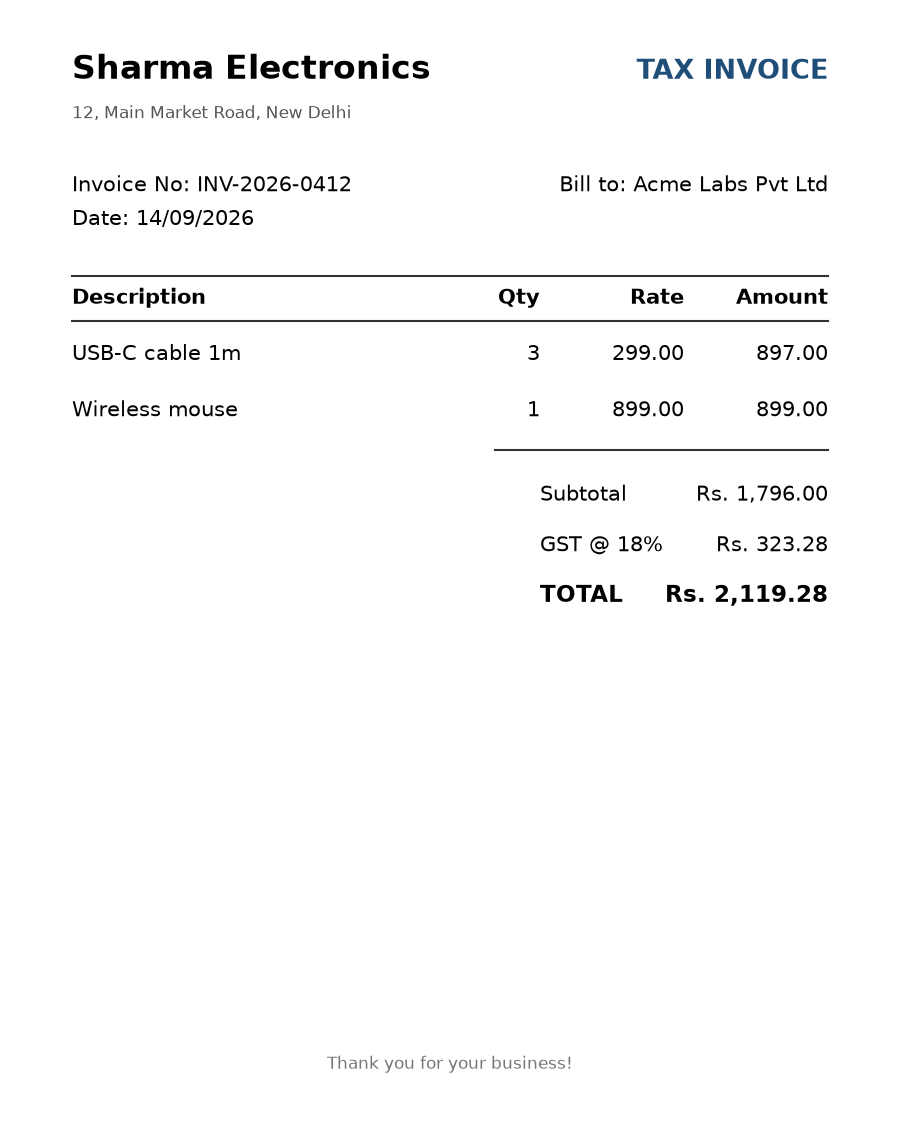

In [2]:
display(Image("samples/invoice_01.png", width=320))

In [3]:
r = ask_doc("What kind of document is this? Who is it from, and what was bought? Two sentences.", "samples/invoice_01.png")
print(r.output_text)
print(f"\ninput tokens: {r.usage.input_tokens} (the image is most of it) | cost ${cost_usd(MODEL, r.usage):.6f}")

This is a tax invoice from Sharma Electronics, billed to Acme Labs Pvt Ltd. It lists three 1-meter USB-C cables and one wireless mouse.

input tokens: 1279 (the image is most of it) | cost $0.000145


In [4]:
# `detail` controls how many patches the image becomes. "low" is cheap but sees less.
for detail in ["low", "high"]:
    r = ask_doc("What is the TOTAL? Number only.", "samples/invoice_06.png", detail=detail)
    print(f"detail={detail:<5} answer={r.output_text:<10} input tokens={r.usage.input_tokens}")

detail=low   answer=2,867.55   input tokens=264


detail=high  answer=2,867.55   input tokens=1267


**Takeaway:** an image is just more input tokens. Check `usage.input_tokens` for *your* images and model: the cost per image is different for every model (see the docs' image token table).

## 2. Image vs PDF inputs

PDFs go in as `input_file`. The API pulls out the **text layer** *and* renders **page images** when the model can see. A **scanned** PDF has no text layer: it is just a picture inside a PDF.

In [5]:
for path in ["samples/invoice_05.pdf", "samples/scanned_invoice.pdf"]:
    r = ask_doc("Vendor name and total amount? One line.", path)
    print(f"{path:<30} {r.output_text:<45} input tokens: {r.usage.input_tokens}")

samples/invoice_05.pdf         CloudNine Software LLC — $169.00              input tokens: 169


samples/scanned_invoice.pdf    Fresh Basket Grocers — Rs. 2,867.55           input tokens: 6027


**Takeaway:** a text PDF here cost ~170 tokens, the scanned one ~6,000: the model had to *look* at the page instead of reading its text. For big volumes of digital PDFs, extracting the text yourself (e.g. `pypdf`) is cheaper still. Use vision when the layout matters or the document is a scan or photo.

## 3. Document understanding: tables and charts

Invoices are tables. Reports are charts. The model can read both, but **let the model read and let your code calculate**.

In [6]:
r = ask_doc("Return the line-item table of this invoice as a Markdown table. Copy the values exactly.", "samples/invoice_02.png")
print(r.output_text)

| Description | Qty | Rate | Amount |
|---|---:|---:|---:|
| A4 paper ream | 5 | 320.00 | 1,600.00 |
| Gel pens (box of 10) | 2 | 150.00 | 300.00 |
| Stapler | 1 | 245.00 | 245.00 |
| Sticky notes | 6 | 40.00 | 240.00 |


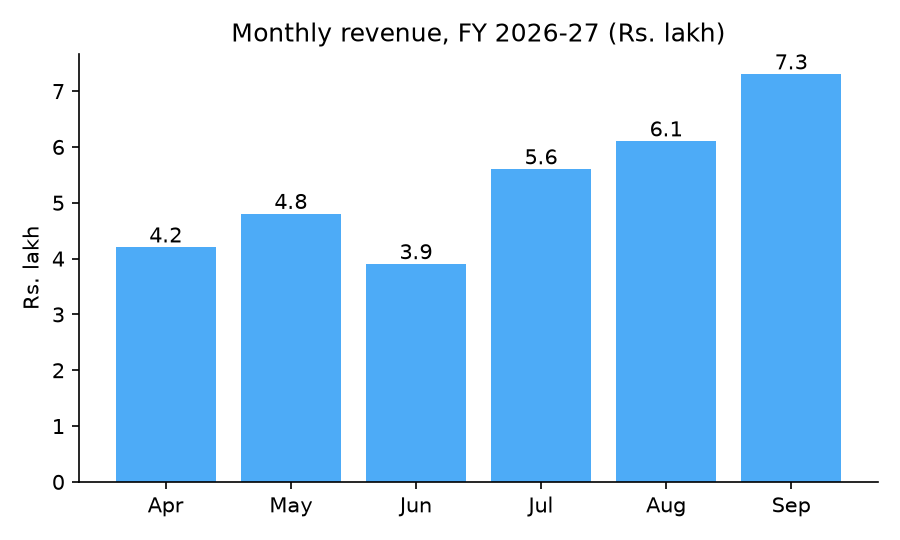

In [7]:
display(Image("samples/revenue_chart.png", width=420))

In [8]:
class Bar(BaseModel):
    month: str
    value: float

class ChartData(BaseModel):
    title: str
    unit: str
    bars: list[Bar]

r = client.responses.parse(model=MODEL, **FAST, text_format=ChartData, input=[{"role": "user", "content": [
    {"type": "input_text", "text": "Extract the data from this chart."}, doc_part("samples/revenue_chart.png")]}])
chart = r.output_parsed
print(chart.title, "|", chart.unit)
print([(b.month, b.value) for b in chart.bars])

# The model READ the numbers. Python does the MATH:
first, last = chart.bars[0], chart.bars[-1]
print(f"growth {first.month} -> {last.month}: {(last.value / first.value - 1) * 100:.1f}%")
print("best month:", max(chart.bars, key=lambda b: b.value).month)

Monthly revenue, FY 2026-27 | Rs. lakh
[('Apr', 4.2), ('May', 4.8), ('Jun', 3.9), ('Jul', 5.6), ('Aug', 6.1), ('Sep', 7.3)]
growth Apr -> Sep: 73.8%
best month: Sep


**Takeaway:** turn a chart or table into **data** first (structured output), then compute in code. Arithmetic done "in the model's head" is where vision answers go wrong.

## 4. Structured extraction with Pydantic

Same idea as Day 05, now with an image as input. The Pydantic model is the **contract**: the API is forced to return JSON that fits it.

In [9]:
class LineItem(BaseModel):
    description: str
    quantity: float
    unit_price: float
    amount: float

class Invoice(BaseModel):
    vendor_name: str
    invoice_number: str
    invoice_date: date = Field(description="The invoice date, as YYYY-MM-DD")
    currency: str = Field(description="ISO code, e.g. INR or USD")
    line_items: list[LineItem]
    subtotal: float
    tax: float
    total: float

PROMPTS = {"v1": "Extract the invoice. Copy numbers exactly as printed. Do not calculate or correct anything."}

def extract(path, model=MODEL, prompt_version="v1", **kwargs):
    r = client.responses.parse(model=model, text_format=Invoice, instructions=PROMPTS[prompt_version],
                               input=[{"role": "user", "content": [doc_part(path)]}], **kwargs)
    return r.output_parsed, r

inv, r = extract("samples/invoice_02.png", **FAST)
print(inv.model_dump_json(indent=2))

{
  "vendor_name": "Kapoor Stationers",
  "invoice_number": "KS/889",
  "invoice_date": "2026-10-02",
  "currency": "INR",
  "line_items": [
    {
      "description": "A4 paper ream",
      "quantity": 5.0,
      "unit_price": 320.0,
      "amount": 1600.0
    },
    {
      "description": "Gel pens (box of 10)",
      "quantity": 2.0,
      "unit_price": 150.0,
      "amount": 300.0
    },
    {
      "description": "Stapler",
      "quantity": 1.0,
      "unit_price": 245.0,
      "amount": 245.0
    },
    {
      "description": "Sticky notes",
      "quantity": 6.0,
      "unit_price": 40.0,
      "amount": 240.0
    }
  ],
  "subtotal": 2385.0,
  "tax": 286.2,
  "total": 2671.2
}


Note `invoice_date` is a real `date` and the printed date was "02 Oct 2026": the model normalised the format for us. And we told it **not to correct the math**: we want what is printed. Checking the math is *our* job (next section).

## 5. Schema validation vs business-rule validation

| | Schema validation | Business-rule validation |
|---|---|---|
| Asks | Is the **shape** right? | Is the **content** believable? |
| Example | `total` is a number, `line_items` is a list | `subtotal + tax == total` |
| Who | Pydantic / the API (automatic) | Your code (you write the rules) |
| On failure | Retry or reject | Flag for a human |

In [10]:
# Schema validation: catches the wrong SHAPE
bad = {"vendor_name": "X", "invoice_number": "1", "invoice_date": "30/02/2026", "currency": "INR",
       "line_items": [], "subtotal": "abc", "tax": 0, "total": 0}
try:
    Invoice.model_validate(bad)
except ValidationError as e:
    for err in e.errors():
        print(err["loc"], "->", err["msg"])

('invoice_date',) -> Input should be a valid date or datetime, invalid character in year
('subtotal',) -> Input should be a valid number, unable to parse string as a number


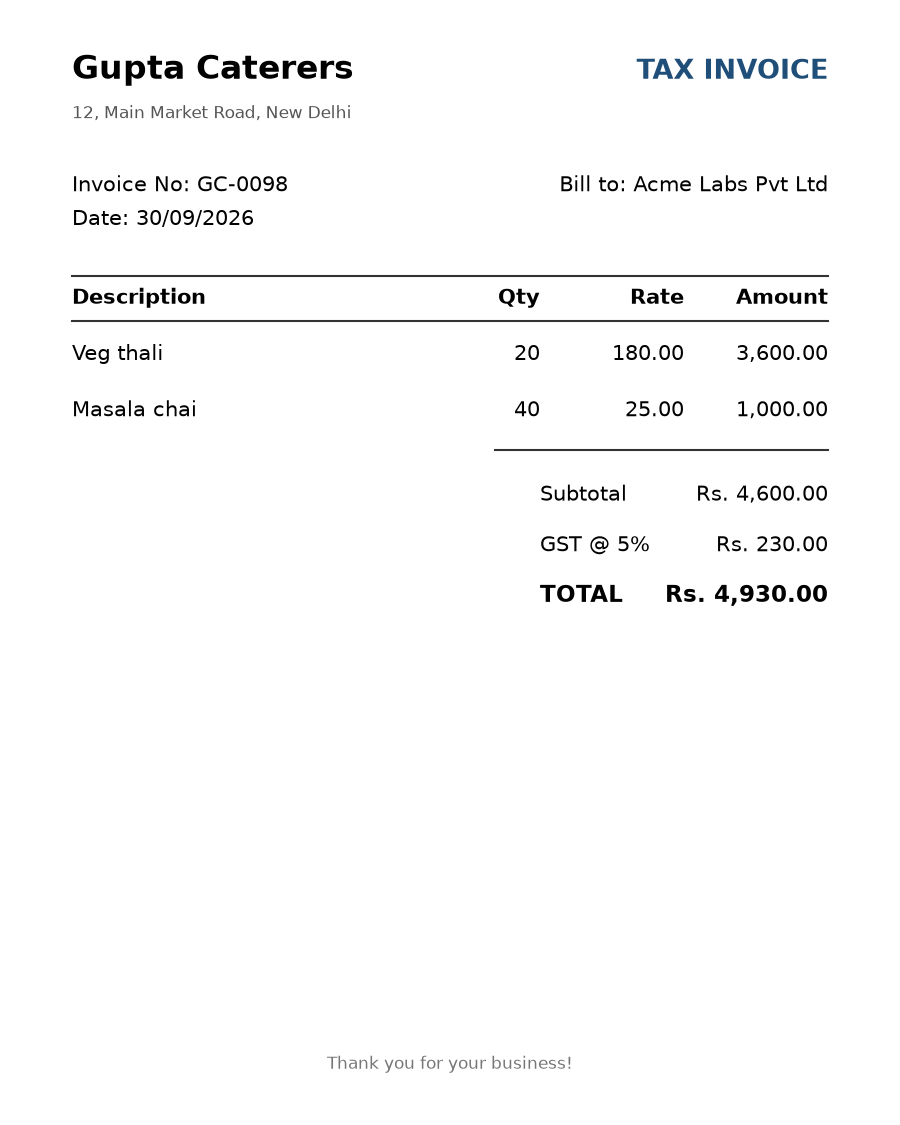

subtotal 4600.0 + tax 230.0 = 4830.0, but printed total = 4930.0
schema: OK  | business rules: ['total_mismatch', 'date_in_future']


In [11]:
GST_RATES = {0, 5, 12, 18, 28}

def check_rules(inv: Invoice) -> list[str]:
    """Business rules: valid JSON can still be a wrong (or fraudulent) invoice."""
    errors = []
    close = lambda a, b: abs(a - b) <= 1.0      # allow rounding by up to 1 unit
    for item in inv.line_items:
        if not close(item.quantity * item.unit_price, item.amount):
            errors.append(f"line_amount_mismatch: {item.description}")
    if not close(sum(i.amount for i in inv.line_items), inv.subtotal):
        errors.append("subtotal_mismatch")
    if not close(inv.subtotal + inv.tax, inv.total):
        errors.append("total_mismatch")
    if inv.currency == "INR" and inv.subtotal and round(inv.tax / inv.subtotal * 100) not in GST_RATES:
        errors.append("unusual_gst_rate")
    if inv.invoice_date > date.today():
        errors.append("date_in_future")
    if not inv.line_items:
        errors.append("no_line_items")
    return errors

display(Image("samples/invoice_04.png", width=300))
inv, _ = extract("samples/invoice_04.png", **FAST)
print(f"subtotal {inv.subtotal} + tax {inv.tax} = {inv.subtotal + inv.tax}, but printed total = {inv.total}")
print("schema: OK  | business rules:", check_rules(inv) or "OK")

**Takeaway:** the schema passed, the JSON is perfect, and the invoice is still wrong (the vendor's total is ₹100 too high). Only a business rule catches that. In production: **schema fail → retry; rule fail → human review queue**.

Also look at `date_in_future` (if it shows up in your run): the model turned "30/09/2026" into the year 3009. Rules catch the **model's** mistakes too, not only the vendor's. We find the cause in section 7.

## 6. Golden dataset and test cases

"It looked right on the one invoice I tried" is not testing. A **golden dataset** is a set of real inputs with the **correct answer written down** by a human. Ours: 6 invoices with different layouts, a bad phone photo, a PDF, a long one, and one with a wrong total.

In [12]:
golden = json.loads(Path("golden.json").read_text())
pd.DataFrame([{"file": g["file"], "vendor": g["expected"]["vendor_name"], "items": len(g["expected"]["line_items"]),
               "total": g["expected"]["total"], "rule that should fire": ", ".join(g["expected_rule_errors"]) or "-"}
              for g in golden])

,file,vendor,items,total,rule that should fire
0,invoice_01.png,Sharma Electronics,2,2119.28,-
1,invoice_02.png,Kapoor Stationers,4,2671.20,-
2,invoice_03.png,Mehta Hardware,3,1581.20,-
3,invoice_04.png,Gupta Caterers,2,4930.00,total_mismatch
4,invoice_05.pdf,CloudNine Software LLC,2,169.00,-
5,invoice_06.png,Fresh Basket Grocers,8,2867.55,-


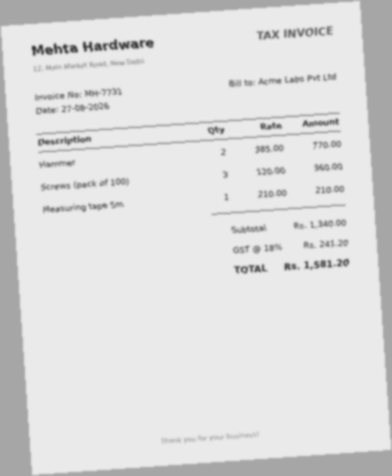

In [13]:
display(Image("samples/invoice_03.png", width=260))  # the hard case: small, tilted, blurry

Good golden sets: start with 20-50 **real** documents, cover the **hard cases** (bad scans, odd layouts, edge cases) on purpose, and add every production failure you find. Never tune your prompt on the same examples you score with.

## 7. Evaluation metrics and failure analysis

Score **each field separately**: "70% correct" hides *which* field is broken.

In [14]:
FIELDS = ["vendor_name", "invoice_number", "invoice_date", "currency", "subtotal", "tax", "total", "line_items"]

def same(field, expected, got):
    if field in ("subtotal", "tax", "total"):
        return abs(float(expected) - float(got)) < 0.01
    if field == "line_items":     # same count, and every row's numbers match
        return len(expected) == len(got) and all(
            abs(e["quantity"] - g["quantity"]) < 0.01 and abs(e["amount"] - g["amount"]) < 0.01
            for e, g in zip(expected, got))
    return str(expected).strip().lower() == str(got).strip().lower()

def run_eval(model=MODEL, prompt_version="v1", **kwargs):
    rows = []
    for g in golden:
        start = time.perf_counter()
        inv, r = extract(f"samples/{g['file']}", model=model, prompt_version=prompt_version, **kwargs)
        got = inv.model_dump(mode="json")
        row = {"file": g["file"], "ms": round((time.perf_counter() - start) * 1000), "usd": cost_usd(model, r.usage), "diffs": []}
        for f in FIELDS:
            row[f] = same(f, g["expected"][f], got[f])
            if not row[f]:
                row["diffs"].append(f"{f}: expected {g['expected'][f]!r}, got {got[f]!r}")
        row["rules_ok"] = sorted(e.split(":")[0] for e in check_rules(inv)) == g["expected_rule_errors"]
        rows.append(row)
    return pd.DataFrame(rows)

baseline = run_eval(**FAST)
baseline[["file"] + FIELDS + ["rules_ok"]]

,file,vendor_name,invoice_number,invoice_date,currency,subtotal,tax,total,line_items,rules_ok
0,invoice_01.png,True,True,False,True,True,True,True,True,True
1,invoice_02.png,True,True,True,True,True,True,True,True,True
2,invoice_03.png,True,False,False,True,True,True,True,True,True
3,invoice_04.png,True,True,False,True,True,True,True,True,False
4,invoice_05.pdf,True,True,True,True,True,True,True,True,True
5,invoice_06.png,True,True,False,True,True,True,True,True,True


In [15]:
def summary(df):
    field_acc = df[FIELDS].mean()
    return {"field_accuracy": round(float(field_acc.mean()), 3),            # all fields of all docs
            "doc_exact_match": round(float(df[FIELDS].all(axis=1).mean()), 3),  # every field right
            "rules_correct": round(float(df["rules_ok"].mean()), 3),
            "p50_ms": int(df["ms"].median()), "usd_per_doc": round(float(df["usd"].mean()), 6)}

print(summary(baseline))
print("\nper-field accuracy:")
print(baseline[FIELDS].mean().round(2).to_string())

{'field_accuracy': 0.896, 'doc_exact_match': 0.333, 'rules_correct': 0.833, 'p50_ms': 2227, 'usd_per_doc': 0.000197}

per-field accuracy:
vendor_name       1.00
invoice_number    0.83
invoice_date      0.33
currency          1.00
subtotal          1.00
tax               1.00
total             1.00
line_items        1.00


In [16]:
# Failure analysis: look at every miss, then group them by CAUSE
for _, row in baseline.iterrows():
    for d in row["diffs"]:
        print(f"{row['file']}: {d}")

invoice_01.png: invoice_date: expected '2026-09-14', got '1409-09-14'
invoice_03.png: invoice_number: expected 'MH-7731', got 'MH-773'
invoice_03.png: invoice_date: expected '2026-08-27', got '2026-02-27'
invoice_04.png: invoice_date: expected '2026-09-30', got '3009-02-20'
invoice_06.png: invoice_date: expected '2026-10-11', got '1110-11-10'


**Failure analysis** = read every miss and give it a cause, then fix the **biggest cause** first, not the last one you saw. In our run:

| Cause | Misses | Fix |
|---|---|---|
| Day-first dates (`14/09/2026` came back as year 1409 or 3009) | most | tell the model the date format (prompt) |
| Blurry, tilted photo (`MH-7731` read as `MH-7733`) | 1-2 | better scan; flag low-quality images for review |

Metrics that matter for extraction: **field accuracy**, **document exact-match** (straight-through processing rate), **rule-check accuracy**, plus **latency** and **cost per document**.

## 8. Regression testing for prompts and models

Any change (new prompt, new model, cheaper settings) can fix one thing and silently break another. A **regression test** reruns the golden set and compares with the saved baseline **before** you ship.

In [17]:
Path("eval_baseline.json").write_text(json.dumps(summary(baseline), indent=2))

def regression_gate(candidate_df, baseline_path="eval_baseline.json", max_drop=0.0):
    base = json.loads(Path(baseline_path).read_text())
    cand = summary(candidate_df)
    ok = True
    for metric in ["field_accuracy", "doc_exact_match", "rules_correct"]:
        drop = base[metric] - cand[metric]
        status = "FAIL" if drop > max_drop else "ok"
        ok &= status == "ok"
        print(f"{metric:<16} baseline {base[metric]:.3f} -> candidate {cand[metric]:.3f}  {status}")
    print(f"{'usd_per_doc':<16} baseline {base['usd_per_doc']:.6f} -> candidate {cand['usd_per_doc']:.6f}")
    print("\nGATE:", "PASS, safe to ship" if ok else "FAIL, do not ship")
    return ok

In [18]:
# Change 1: fix the biggest failure cause from section 7, the dates
PROMPTS["v2"] = PROMPTS["v1"] + (" Dates on these invoices are written day first (DD/MM/YYYY, DD-MM-YYYY, DD.MM.YYYY):"
                                 " convert them to YYYY-MM-DD.")
v2 = run_eval(prompt_version="v2", **FAST)
if regression_gate(v2):
    Path("eval_baseline.json").write_text(json.dumps(summary(v2), indent=2))   # v2 is the new bar to beat
print("\nstill wrong:", *[f"{r.file}: {d}" for r in v2.itertuples() for d in r.diffs], sep="\n")

field_accuracy   baseline 0.896 -> candidate 0.958  ok
doc_exact_match  baseline 0.333 -> candidate 0.833  ok
rules_correct    baseline 0.833 -> candidate 1.000  ok
usd_per_doc      baseline 0.000197 -> candidate 0.000193

GATE: PASS, safe to ship

still wrong:
invoice_03.png: invoice_number: expected 'MH-7731', got 'MH-773'
invoice_03.png: invoice_date: expected '2026-08-27', got '2026-07-27'


In [19]:
# Change 2: same prompt, a different model. gpt-4.1-nano has the same input price as gpt-6-luna
nano = run_eval(model="gpt-4.1-nano", prompt_version="v2")
regression_gate(nano)

field_accuracy   baseline 0.958 -> candidate 0.833  FAIL
doc_exact_match  baseline 0.833 -> candidate 0.167  FAIL
rules_correct    baseline 1.000 -> candidate 0.833  FAIL
usd_per_doc      baseline 0.000193 -> candidate 0.000262

GATE: FAIL, do not ship


False

**Takeaway:** treat prompts and model names like code: version them (`PROMPTS["v2"]`), and run the golden set on every change, e.g. a `pytest` in CI that fails the build when `regression_gate` fails. A lower price per token is not a lower price per document: models turn the same image into very different token counts.

With only 6 documents, one flaky answer moves a metric a lot. Real golden sets need more documents, and it's worth running each one 2-3 times.

## 9. Observability: tracing every call

Evals tell you how the app does on **your** test set. **Observability** tells you what it does on **real traffic**.

- A **trace** = one user request, end to end (one invoice processed).
- A **span** = one step inside it (load file, LLM call, validation), with its timing.
- For every LLM span, log: **input** (or a reference to it), **output**, **model**, **latency**, **tokens**, **cost**, **status / error**, **prompt version**.

Below is a 30-line tracer that writes one JSON line per span. Tools like Langfuse, LangSmith or OpenTelemetry do the same thing with a UI on top.

In [20]:
LOG = Path("logs/traces.jsonl")
LOG.parent.mkdir(exist_ok=True)
LOG.write_text("")                      # start fresh for the demo
_current = {"trace_id": None, "parent": None}

@contextmanager
def span(name, **attrs):
    """Time a step, catch its error, and append one JSON line to the log."""
    rec = {"trace_id": _current["trace_id"], "span_id": uuid.uuid4().hex[:8], "parent": _current["parent"],
           "name": name, **attrs, "status": "ok", "error": None}
    prev_parent, _current["parent"] = _current["parent"], rec["span_id"]
    start = time.perf_counter()
    try:
        yield rec                           # the step can add fields: tokens, cost, output...
    except Exception as e:
        rec["status"], rec["error"] = "error", f"{type(e).__name__}: {str(e)[:200]}"
        raise
    finally:
        rec["latency_ms"] = round((time.perf_counter() - start) * 1000)
        _current["parent"] = prev_parent
        with LOG.open("a") as f:
            f.write(json.dumps(rec, default=str) + "\n")

In [21]:
def process_invoice(path, model=MODEL, prompt_version="v2", **kwargs):
    """The production pipeline, fully traced. Never raises: returns a result the API can send back."""
    _current["trace_id"] = uuid.uuid4().hex[:12]
    try:
        with span("process_invoice", file=Path(path).name):
            with span("llm.extract", model=model, prompt_version=prompt_version) as s:
                r = client.responses.parse(model=model, text_format=Invoice, instructions=PROMPTS[prompt_version],
                                           input=[{"role": "user", "content": [doc_part(path)]}], **kwargs)
                s.update(response_id=r.id, input_tokens=r.usage.input_tokens, output_tokens=r.usage.output_tokens,
                         cost_usd=round(cost_usd(model, r.usage), 6), response_status=r.status)
                if r.output_parsed is None:
                    raise ValueError(f"no parsed output (status={r.status}, {r.incomplete_details})")
                s["output"] = r.output_parsed.model_dump(mode="json")
            with span("validate.rules") as s:
                s["rule_errors"] = check_rules(r.output_parsed)
        decision = "human_review" if s["rule_errors"] else "auto_approve"
        return {"trace_id": _current["trace_id"], "decision": decision, "rule_errors": s["rule_errors"]}
    except Exception as e:
        return {"trace_id": _current["trace_id"], "decision": "failed", "error": type(e).__name__}

print(process_invoice("samples/invoice_01.png", **FAST))
print(process_invoice("samples/invoice_04.png", **FAST))

{'trace_id': '2a68a6f085b7', 'decision': 'auto_approve', 'rule_errors': []}


{'trace_id': 'e910b71abd82', 'decision': 'human_review', 'rule_errors': ['total_mismatch']}


In [22]:
# One trace = the spans that share a trace_id. Children finish (and are logged) before the parent.
spans = [json.loads(l) for l in LOG.read_text().splitlines()]
for s in spans[:3]:
    print({k: v for k, v in s.items() if k != "output"})

{'trace_id': '2a68a6f085b7', 'span_id': '675aeabd', 'parent': '113d3da1', 'name': 'llm.extract', 'model': 'gpt-6-luna', 'prompt_version': 'v2', 'status': 'ok', 'error': None, 'response_id': 'resp_05a5dbd45b3f0e5a006ad31540863c87d2b69be9881f35cee9', 'input_tokens': 1525, 'output_tokens': 114, 'cost_usd': 0.00021, 'response_status': 'completed', 'latency_ms': 1844}
{'trace_id': '2a68a6f085b7', 'span_id': '2938080a', 'parent': '113d3da1', 'name': 'validate.rules', 'status': 'ok', 'error': None, 'rule_errors': [], 'latency_ms': 0}
{'trace_id': '2a68a6f085b7', 'span_id': '113d3da1', 'parent': None, 'name': 'process_invoice', 'file': 'invoice_01.png', 'status': 'ok', 'error': None, 'latency_ms': 1845}


**What NOT to log:** API keys, full base64 images (huge; store the file and log its path or ID), and personal data you're not allowed to keep. Invoices contain names, addresses and tax IDs: mask or restrict access to logs.

## 10. Monitoring failures and cost

Now simulate a day of traffic: the good invoices, plus the kinds of failures that really happen.

In [23]:
traffic = [(f"samples/{g['file']}", MODEL, FAST) for g in golden] + [
    ("samples/revenue_chart.png", MODEL, FAST),                                   # user uploads the wrong document
    ("samples/invoice_06.png", MODEL, {**FAST, "max_output_tokens": 60}),        # output limit too small
    ("samples/invoice_02.png", "gpt-6-lunaa", FAST),                             # typo in the model name (bad deploy)
]
results = [process_invoice(path, model=m, **kw) for path, m, kw in traffic]
pd.DataFrame(results)

,trace_id,decision,rule_errors,error
0,6cfdd542b072,auto_approve,[],NaN
1,32aebabd314b,auto_approve,[],NaN
2,9f2e6d12f8aa,auto_approve,[],NaN
3,1cf7d1900e26,human_review,[total_mismatch],NaN
4,af586d5e5d89,auto_approve,[],NaN
5,8acbbb698c88,auto_approve,[],NaN
6,00e9392324ea,failed,NaN,ValidationError
7,4cb562be45c7,failed,NaN,ValidationError
8,95b4b02a67be,failed,NaN,NotFoundError


In [24]:
df = pd.DataFrame(json.loads(l) for l in LOG.read_text().splitlines())
llm = df[df.name == "llm.extract"]
top = df[df.name == "process_invoice"]

print(f"requests:        {len(top)}")
print(f"error rate:      {(top.status == 'error').mean():.0%}")
print(f"LLM latency:     P50 {llm.latency_ms.median():.0f} ms | P95 {llm.latency_ms.quantile(0.95):.0f} ms")
print(f"total cost:      ${llm.cost_usd.sum():.5f}  (${llm.cost_usd.mean():.6f} per call)")
print("\nerrors by type:")
print(llm[llm.status == "error"].error.str.split(":").str[0].value_counts().to_string())

requests:        11
error rate:      27%
LLM latency:     P50 1858 ms | P95 2962 ms
total cost:      $0.00158  ($0.000197 per call)

errors by type:
error
ValidationError    2
NotFoundError      1


In production these numbers become **dashboards** and **alerts**: error rate above 2%, P95 latency above 10 s, cost per day above budget, a sudden jump in `human_review` decisions (the model got worse, or the vendor changed their invoice layout). The chart image is the sneaky one. In one of our runs it failed the schema (the model wrote the date `0000-01-01`). In another it "succeeded" with made-up invoice fields that only a business rule caught. Neither is a clear "this is not an invoice" message to the user: that needs a check of its own (e.g. an `is_invoice` field).

## 11. Debugging a failed request

A user says "my upload failed". Find the trace, read the spans, find the cause.

In [25]:
def show_trace(trace_id):
    for s in (json.loads(l) for l in LOG.read_text().splitlines()):
        if s["trace_id"] == trace_id:
            keep = ["name", "status", "latency_ms", "model", "input_tokens", "output_tokens", "response_status", "error", "rule_errors"]
            print({k: s.get(k) for k in keep if s.get(k) is not None})

for res in results:
    if res["decision"] in ("failed", "human_review"):
        print(f"--- trace {res['trace_id']} -> {res['decision']}")
        show_trace(res["trace_id"])

--- trace 1cf7d1900e26 -> human_review
{'name': 'llm.extract', 'status': 'ok', 'latency_ms': 2814, 'model': 'gpt-6-luna', 'input_tokens': 1525, 'output_tokens': 112, 'response_status': 'completed'}
{'name': 'validate.rules', 'status': 'ok', 'latency_ms': 0, 'rule_errors': ['total_mismatch']}
{'name': 'process_invoice', 'status': 'ok', 'latency_ms': 2815}
--- trace 00e9392324ea -> failed
{'name': 'llm.extract', 'status': 'error', 'latency_ms': 1556, 'model': 'gpt-6-luna', 'error': "ValidationError: 1 validation error for Invoice\ninvoice_date\n  Input should be a valid date in the format YYYY-MM-DD, year 0 is out of range [type=date_parsing, input_value='0000-01-01', input_type=str]\n    For furthe"}
{'name': 'process_invoice', 'status': 'error', 'latency_ms': 1557, 'error': "ValidationError: 1 validation error for Invoice\ninvoice_date\n  Input should be a valid date in the format YYYY-MM-DD, year 0 is out of range [type=date_parsing, input_value='0000-01-01', input_type=str]\n    For 

**Debugging checklist**

| Symptom in the trace | Likely cause | Fix |
|---|---|---|
| `NotFoundError` (404), no tokens used | wrong model name / config | fix config; alert on deploy |
| `ValidationError: Invalid JSON: EOF while parsing` | output cut off by `max_output_tokens`: the JSON never finished | raise the limit; shorter schema |
| `AuthenticationError` (401) | bad or expired key | rotate the key; never retry |
| `RateLimitError` (429) / timeouts | too much traffic | backoff + retry (Day 06) |
| `ValidationError` on one field (e.g. year 0) | not an invoice, or unreadable | tell the user; add an `is_invoice` check |
| status ok, but rule errors | bad document or bad extraction | open the image; human review |
| status ok, rules ok, wrong answer | silent failure | add the doc to the golden set |

Always go **trace → span → input → output**. Then turn every real failure into a new golden test case, so it can never come back unnoticed.

## Homework

1. Photograph or download **10 real invoices or receipts** (yours, with personal data removed), and write their correct values in `golden.json` format.
2. Run `run_eval` on them. Write down every miss and group the misses by cause.
3. Fix the biggest cause, rerun, and use `regression_gate` to show you didn't break anything else.